# CNN

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from PIL import ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True

In [4]:
EPOCHS = 10
BATCH_SIZE = 32
LR = 0.001
IMG_SIZE = 224

import random

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

ROOT = "../.."
DATA_CSV_LOC = os.path.join(ROOT, "DATA_PP")

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print(device)

mps


In [5]:
train_df = pd.read_csv(DATA_CSV_LOC + "/train.csv")
val_df = pd.read_csv(DATA_CSV_LOC + "/val.csv")
test_df = pd.read_csv(DATA_CSV_LOC + "/test.csv")

classes = sorted(train_df["label"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

print(class_to_idx)
print(len(train_df), len(val_df), len(test_df))

{'ABE': 0, 'BLA': 1, 'FGC': 2, 'HAC': 3, 'KSC': 4, 'LYI': 5, 'normal': 6}
103538 22187 22187


In [4]:
"""import os
import shutil

source_dir = "../../DATA/bone_marrow_cell_dataset"
output_dir = "../../DATA_PP"

abnormal = {"ABE", "BLA", "FGC", "HAC", "KSC", "LYI"}
exclude = {"ART", "NIF", "OTH"}

copied = 0

for category in os.listdir(source_dir):
    if category in exclude:
        continue

    label = category if category in abnormal else "normal"
    src_folder = os.path.join(source_dir, category)
    dst_folder = os.path.join(output_dir, label)

    os.makedirs(dst_folder, exist_ok=True)

    for root, dirs, files in os.walk(src_folder):
        for filename in files:
            src = os.path.join(root, filename)
            dst = os.path.join(dst_folder, filename)

            if os.path.exists(dst):
                continue

            shutil.copy2(src, dst)
            copied += 1

print("New images copied:", copied) """

'import os\nimport shutil\n\nsource_dir = "../../DATA/bone_marrow_cell_dataset"\noutput_dir = "../../DATA_PP"\n\nabnormal = {"ABE", "BLA", "FGC", "HAC", "KSC", "LYI"}\nexclude = {"ART", "NIF", "OTH"}\n\ncopied = 0\n\nfor category in os.listdir(source_dir):\n    if category in exclude:\n        continue\n\n    label = category if category in abnormal else "normal"\n    src_folder = os.path.join(source_dir, category)\n    dst_folder = os.path.join(output_dir, label)\n\n    os.makedirs(dst_folder, exist_ok=True)\n\n    for root, dirs, files in os.walk(src_folder):\n        for filename in files:\n            src = os.path.join(root, filename)\n            dst = os.path.join(dst_folder, filename)\n\n            if os.path.exists(dst):\n                continue\n\n            shutil.copy2(src, dst)\n            copied += 1\n\nprint("New images copied:", copied) '

In [6]:
for name, df in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    missing = 0

    for filepath in df["filepath"]:
        full_path = os.path.join(ROOT, filepath)

        if not os.path.isfile(full_path):
            missing += 1

    print(name, "- Missing images:", missing)

Train - Missing images: 0
Validation - Missing images: 0
Test - Missing images: 0


In [9]:
class BoneMarrowDataset(Dataset):
    def __init__(self, df, root, transform=None):
        self.df = df.reset_index(drop=True)
        self.root = root
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_path = os.path.join(self.root, row["filepath"])
        image = Image.open(image_path).convert("RGB")

        label = class_to_idx[row["label"]]

        if self.transform:
            image = self.transform(image)

        return image, label

In [10]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

In [11]:
train_dataset = BoneMarrowDataset(train_df, ROOT, train_transform)
val_dataset = BoneMarrowDataset(val_df, ROOT, val_transform)
test_dataset = BoneMarrowDataset(test_df, ROOT, val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(len(train_dataset), len(val_dataset), len(test_dataset))


103538 22187 22187


In [14]:
class BoneMarrowCNN(nn.Module):
    def __init__(self, num_classes=7, dropout=0.3):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [15]:
class_counts = train_df["label"].value_counts()

weights = []

for c in classes:
    weight = (len(train_df) / (len(classes) * class_counts[c])) ** 0.5
    weights.append(weight)

class_weights = torch.tensor(
    weights, dtype=torch.float32
).to(device)

print("Updated class weights:")
for c, w in zip(classes, weights):
    print(c, round(w, 4))

Updated class weights:
ABE 49.6507
BLA 1.3285
FGC 21.1711
HAC 7.1915
KSC 22.2045
LYI 18.1299
normal 0.3951


In [16]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = correct / total

    return avg_loss, accuracy

In [17]:
def validate(model, loader, criterion, device):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            all_preds.extend(predictions.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / total
    accuracy = correct / total
    macro_f1 = f1_score(
        all_labels,
        all_preds,
        labels=list(range(len(classes))),
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1


## Train CNN

In [13]:
model = BoneMarrowCNN(num_classes=7).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

In [14]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []
val_f1_scores = []

best_f1 = -1

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_acc, val_f1 = validate(
        model, val_loader, criterion, device
    )

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)
    val_f1_scores.append(val_f1)

    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f} | Macro F1: {val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1 = val_f1
        torch.save(model.state_dict(), "best_cnn.pth")
        print("Saved best model!")

    print()


Epoch 1/10
Train Loss: 0.7619 | Train Accuracy: 0.9114
Val Loss: 0.7110 | Val Accuracy: 0.8835 | Macro F1: 0.1517
Saved best model!

Epoch 2/10
Train Loss: 0.7065 | Train Accuracy: 0.9040
Val Loss: 0.6438 | Val Accuracy: 0.9095 | Macro F1: 0.1544
Saved best model!

Epoch 3/10
Train Loss: 0.6616 | Train Accuracy: 0.8966
Val Loss: 0.5801 | Val Accuracy: 0.9092 | Macro F1: 0.1905
Saved best model!

Epoch 4/10
Train Loss: 0.6038 | Train Accuracy: 0.9006
Val Loss: 0.5448 | Val Accuracy: 0.8989 | Macro F1: 0.2055
Saved best model!

Epoch 5/10
Train Loss: 0.5838 | Train Accuracy: 0.9024
Val Loss: 0.5275 | Val Accuracy: 0.9210 | Macro F1: 0.2433
Saved best model!

Epoch 6/10
Train Loss: 0.5666 | Train Accuracy: 0.9025
Val Loss: 0.5271 | Val Accuracy: 0.9187 | Macro F1: 0.2059

Epoch 7/10
Train Loss: 0.5573 | Train Accuracy: 0.9036
Val Loss: 0.5396 | Val Accuracy: 0.9084 | Macro F1: 0.2414

Epoch 8/10
Train Loss: 0.5433 | Train Accuracy: 0.9055
Val Loss: 0.5008 | Val Accuracy: 0.9165 | Macro F1

In [15]:
model.load_state_dict(
    torch.load("best_cnn.pth", map_location=device, weights_only=True)
)

model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

              precision    recall  f1-score   support

         ABE       0.00      0.00      0.00         1
         BLA       0.60      0.35      0.45      1796
         FGC       0.14      0.14      0.14         7
         HAC       0.00      0.00      0.00        62
         KSC       0.50      0.50      0.50         6
         LYI       0.00      0.00      0.00        10
      normal       0.94      0.98      0.96     20305

    accuracy                           0.93     22187
   macro avg       0.31      0.28      0.29     22187
weighted avg       0.91      0.93      0.91     22187



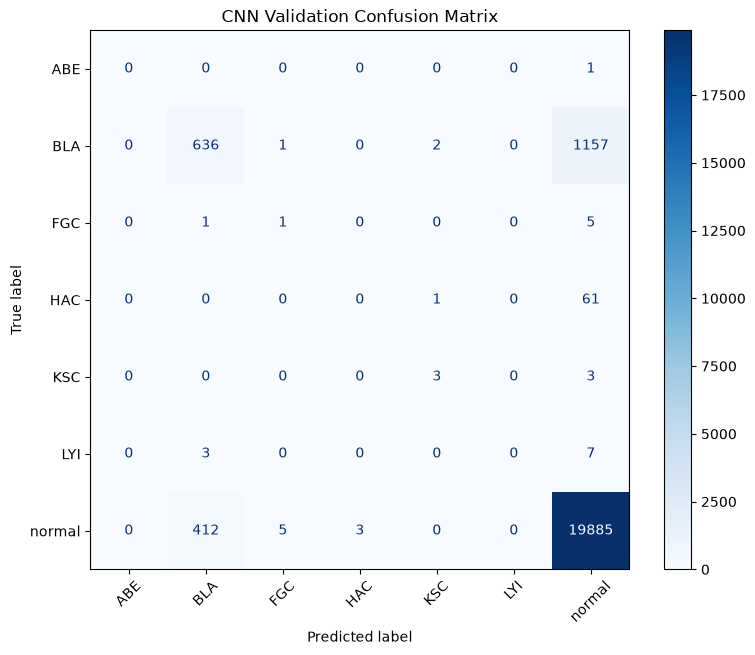

In [16]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(classes)))
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("CNN Validation Confusion Matrix")
plt.xticks(rotation=45)
plt.show()

## Hyperparameter Tuning

### Data Augmentation

In [12]:
augmented_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),
    transforms.ToTensor()
])

augmented_dataset = BoneMarrowDataset(
    train_df, ROOT, augmented_transform
)

augmented_loader = DataLoader(
    augmented_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

In [20]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

augmented_model = BoneMarrowCNN(num_classes=7).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

augmented_optimizer = torch.optim.Adam(
    augmented_model.parameters(), lr=LR
)

In [21]:
aug_train_losses = []
aug_val_losses = []
aug_val_f1_scores = []

best_aug_f1 = -1

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(
        augmented_model, augmented_loader,
        criterion, augmented_optimizer, device
    )

    val_loss, val_acc, val_f1 = validate(
        augmented_model, val_loader, criterion, device
    )

    aug_train_losses.append(train_loss)
    aug_val_losses.append(val_loss)
    aug_val_f1_scores.append(val_f1)

    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f} | Macro F1: {val_f1:.4f}")

    if val_f1 > best_aug_f1:
        best_aug_f1 = val_f1
        torch.save(augmented_model.state_dict(), "best_cnn_augmented.pth")
        print("Saved best augmented model!")

    print()

Epoch 1/10
Train Loss: 0.7562 | Train Accuracy: 0.9098
Val Loss: 0.7159 | Val Accuracy: 0.8611 | Macro F1: 0.1547
Saved best augmented model!

Epoch 2/10
Train Loss: 0.7022 | Train Accuracy: 0.8975
Val Loss: 0.6295 | Val Accuracy: 0.8985 | Macro F1: 0.1675
Saved best augmented model!

Epoch 3/10
Train Loss: 0.6556 | Train Accuracy: 0.8948
Val Loss: 0.5829 | Val Accuracy: 0.9081 | Macro F1: 0.1821
Saved best augmented model!

Epoch 4/10
Train Loss: 0.6222 | Train Accuracy: 0.8969
Val Loss: 0.5726 | Val Accuracy: 0.9190 | Macro F1: 0.1871
Saved best augmented model!

Epoch 5/10
Train Loss: 0.6090 | Train Accuracy: 0.8992
Val Loss: 0.5659 | Val Accuracy: 0.9183 | Macro F1: 0.1970
Saved best augmented model!

Epoch 6/10
Train Loss: 0.5908 | Train Accuracy: 0.9001
Val Loss: 0.5934 | Val Accuracy: 0.9195 | Macro F1: 0.1722

Epoch 7/10
Train Loss: 0.5804 | Train Accuracy: 0.9006
Val Loss: 0.5566 | Val Accuracy: 0.9236 | Macro F1: 0.2306
Saved best augmented model!

Epoch 8/10
Train Loss: 0.56

In [22]:
augmented_model.load_state_dict(
    torch.load("best_cnn_augmented.pth", map_location=device, weights_only=True)
)

augmented_model.eval()

aug_preds = []
aug_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = augmented_model(images)
        predictions = outputs.argmax(dim=1)

        aug_preds.extend(predictions.cpu().numpy())
        aug_labels.extend(labels.numpy())

print(classification_report(
    aug_labels,
    aug_preds,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

              precision    recall  f1-score   support

         ABE       0.00      0.00      0.00         1
         BLA       0.52      0.41      0.46      1796
         FGC       0.12      0.29      0.17         7
         HAC       0.00      0.00      0.00        62
         KSC       1.00      0.33      0.50         6
         LYI       0.00      0.00      0.00        10
      normal       0.95      0.97      0.96     20305

    accuracy                           0.92     22187
   macro avg       0.37      0.28      0.30     22187
weighted avg       0.91      0.92      0.91     22187



## Learning Rate Tuning

In [23]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

lr_model = BoneMarrowCNN(num_classes=7).to(device)

lr_optimizer = torch.optim.Adam(
    lr_model.parameters(),
    lr=0.0005
)

criterion = nn.CrossEntropyLoss(weight=class_weights)

### 0.0005 Learning Rate

In [24]:
lr_train_losses = []
lr_val_losses = []
lr_val_f1_scores = []

best_lr_f1 = -1

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(
        lr_model, augmented_loader,
        criterion, lr_optimizer, device
    )

    val_loss, val_acc, val_f1 = validate(
        lr_model, val_loader, criterion, device
    )

    lr_train_losses.append(train_loss)
    lr_val_losses.append(val_loss)
    lr_val_f1_scores.append(val_f1)

    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f} | Macro F1: {val_f1:.4f}")

    if val_f1 > best_lr_f1:
        best_lr_f1 = val_f1
        torch.save(lr_model.state_dict(), "best_cnn_lr_0005.pth")
        print("Saved best learning rate model!")

    print()

Epoch 1/10
Train Loss: 0.7525 | Train Accuracy: 0.9086
Val Loss: 0.6800 | Val Accuracy: 0.8799 | Macro F1: 0.1584
Saved best learning rate model!

Epoch 2/10
Train Loss: 0.6991 | Train Accuracy: 0.8982
Val Loss: 0.6307 | Val Accuracy: 0.9067 | Macro F1: 0.1648
Saved best learning rate model!

Epoch 3/10
Train Loss: 0.6529 | Train Accuracy: 0.8982
Val Loss: 0.5940 | Val Accuracy: 0.9092 | Macro F1: 0.1782
Saved best learning rate model!

Epoch 4/10
Train Loss: 0.6239 | Train Accuracy: 0.8992
Val Loss: 0.5622 | Val Accuracy: 0.9162 | Macro F1: 0.1860
Saved best learning rate model!

Epoch 5/10
Train Loss: 0.6003 | Train Accuracy: 0.9014
Val Loss: 0.5512 | Val Accuracy: 0.9186 | Macro F1: 0.2313
Saved best learning rate model!

Epoch 6/10
Train Loss: 0.5822 | Train Accuracy: 0.9023
Val Loss: 0.5617 | Val Accuracy: 0.9214 | Macro F1: 0.1837

Epoch 7/10
Train Loss: 0.5665 | Train Accuracy: 0.9028
Val Loss: 0.5403 | Val Accuracy: 0.9243 | Macro F1: 0.2381
Saved best learning rate model!

Epo

### 0.0001 Learning Rate

In [25]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

lr_0001_model = BoneMarrowCNN(num_classes=7).to(device)

lr_0001_criterion = nn.CrossEntropyLoss(weight=class_weights)
lr_0001_optimizer = torch.optim.Adam(
    lr_0001_model.parameters(), lr=0.0001
)

lr_0001_train_losses = []
lr_0001_val_losses = []
lr_0001_val_f1_scores = []

best_lr_0001_f1 = -1
best_lr_0001_epoch = 0

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(
        lr_0001_model, augmented_loader,
        lr_0001_criterion, lr_0001_optimizer, device
    )

    val_loss, val_acc, val_f1 = validate(
        lr_0001_model, val_loader, lr_0001_criterion, device
    )

    lr_0001_train_losses.append(train_loss)
    lr_0001_val_losses.append(val_loss)
    lr_0001_val_f1_scores.append(val_f1)

    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f} | Macro F1: {val_f1:.4f}")

    if val_f1 > best_lr_0001_f1:
        best_lr_0001_f1 = val_f1
        best_lr_0001_epoch = epoch + 1

        torch.save(
            lr_0001_model.state_dict(),
            "best_cnn_lr_0001.pth"
        )
        print("Saved best learning rate model!")

    print()

print("Best Macro F1:", round(best_lr_0001_f1, 4))
print("Best Epoch:", best_lr_0001_epoch)

Epoch 1/10
Train Loss: 0.7789 | Train Accuracy: 0.9149
Val Loss: 0.7124 | Val Accuracy: 0.9149 | Macro F1: 0.1367
Saved best learning rate model!

Epoch 2/10
Train Loss: 0.7256 | Train Accuracy: 0.9104
Val Loss: 0.6782 | Val Accuracy: 0.9135 | Macro F1: 0.1436
Saved best learning rate model!

Epoch 3/10
Train Loss: 0.6987 | Train Accuracy: 0.9044
Val Loss: 0.6590 | Val Accuracy: 0.9113 | Macro F1: 0.1461
Saved best learning rate model!

Epoch 4/10
Train Loss: 0.6835 | Train Accuracy: 0.9007
Val Loss: 0.6440 | Val Accuracy: 0.9062 | Macro F1: 0.1592
Saved best learning rate model!

Epoch 5/10
Train Loss: 0.6713 | Train Accuracy: 0.8984
Val Loss: 0.6340 | Val Accuracy: 0.9127 | Macro F1: 0.1608
Saved best learning rate model!

Epoch 6/10
Train Loss: 0.6558 | Train Accuracy: 0.8988
Val Loss: 0.6355 | Val Accuracy: 0.9146 | Macro F1: 0.1585

Epoch 7/10
Train Loss: 0.6480 | Train Accuracy: 0.8994
Val Loss: 0.6274 | Val Accuracy: 0.9148 | Macro F1: 0.1628
Saved best learning rate model!

Epo

Quick analysis: The augmented CNN with a learning rate of 0.001 performed the best, with a validation macro F1 of 0.2982. Learning rates of 0.0005 and 0.0001 performed worse over 10 epochs. The 0.0001 learning rate may benefit from more training epochs because it makes smaller weight updates.

## Dropout Tuning

In [27]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

dropout_model = BoneMarrowCNN(
    num_classes=7,
    dropout=0.5
).to(device)

dropout_criterion = nn.CrossEntropyLoss(weight=class_weights)

dropout_optimizer = torch.optim.Adam(
    dropout_model.parameters(),
    lr=0.001
)

In [28]:
dropout_train_losses = []
dropout_val_losses = []
dropout_val_f1_scores = []

best_dropout_f1 = -1
best_dropout_epoch = 0
best_dropout_acc = 0

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(
        dropout_model, augmented_loader,
        dropout_criterion, dropout_optimizer, device
    )

    val_loss, val_acc, val_f1 = validate(
        dropout_model, val_loader, dropout_criterion, device
    )

    dropout_train_losses.append(train_loss)
    dropout_val_losses.append(val_loss)
    dropout_val_f1_scores.append(val_f1)

    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f} | Macro F1: {val_f1:.4f}")

    if val_f1 > best_dropout_f1:
        best_dropout_f1 = val_f1
        best_dropout_epoch = epoch + 1
        best_dropout_acc = val_acc

        torch.save(
            dropout_model.state_dict(),
            "best_cnn_dropout_05.pth"
        )
        print("Saved best dropout model!")

    print()

print("Best Macro F1:", round(best_dropout_f1, 4))
print("Best Epoch:", best_dropout_epoch)
print("Accuracy at Best Epoch:", round(best_dropout_acc, 4))

Epoch 1/10
Train Loss: 0.7760 | Train Accuracy: 0.9141
Val Loss: 0.7257 | Val Accuracy: 0.9078 | Macro F1: 0.1431
Saved best dropout model!

Epoch 2/10
Train Loss: 0.7320 | Train Accuracy: 0.9073
Val Loss: 0.6828 | Val Accuracy: 0.9067 | Macro F1: 0.1470
Saved best dropout model!

Epoch 3/10
Train Loss: 0.7019 | Train Accuracy: 0.8993
Val Loss: 0.6283 | Val Accuracy: 0.9070 | Macro F1: 0.1625
Saved best dropout model!

Epoch 4/10
Train Loss: 0.6755 | Train Accuracy: 0.8974
Val Loss: 0.5991 | Val Accuracy: 0.9157 | Macro F1: 0.1791
Saved best dropout model!

Epoch 5/10
Train Loss: 0.6409 | Train Accuracy: 0.9001
Val Loss: 0.5721 | Val Accuracy: 0.9195 | Macro F1: 0.1927
Saved best dropout model!

Epoch 6/10
Train Loss: 0.6184 | Train Accuracy: 0.9011
Val Loss: 0.5943 | Val Accuracy: 0.9226 | Macro F1: 0.1794

Epoch 7/10
Train Loss: 0.6019 | Train Accuracy: 0.9027
Val Loss: 0.5570 | Val Accuracy: 0.9249 | Macro F1: 0.1974
Saved best dropout model!

Epoch 8/10
Train Loss: 0.5956 | Train A

Quick Analysis: 0.3 performs better than 0.5.

## CNN Depth Tuning

The original was a CNN with 3 convolutional blocks. The one we will be experimenting with is 4 blocks to see if that is better than 3 blocks

In [29]:
class DeeperBoneMarrowCNN(nn.Module):
    def __init__(self, num_classes=7, dropout=0.3):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [30]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

deeper_model = DeeperBoneMarrowCNN(
    num_classes=7,
    dropout=0.3
).to(device)

deeper_criterion = nn.CrossEntropyLoss(weight=class_weights)

deeper_optimizer = torch.optim.Adam(
    deeper_model.parameters(),
    lr=0.001
)

In [31]:
deeper_train_losses = []
deeper_val_losses = []
deeper_val_f1_scores = []

best_deeper_f1 = -1
best_deeper_epoch = 0
best_deeper_acc = 0

for epoch in range(EPOCHS):
    train_loss, train_acc = train_one_epoch(
        deeper_model, augmented_loader,
        deeper_criterion, deeper_optimizer, device
    )

    val_loss, val_acc, val_f1 = validate(
        deeper_model, val_loader, deeper_criterion, device
    )

    deeper_train_losses.append(train_loss)
    deeper_val_losses.append(val_loss)
    deeper_val_f1_scores.append(val_f1)

    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f} | Macro F1: {val_f1:.4f}")

    if val_f1 > best_deeper_f1:
        best_deeper_f1 = val_f1
        best_deeper_epoch = epoch + 1
        best_deeper_acc = val_acc

        torch.save(
            deeper_model.state_dict(),
            "best_cnn_deeper.pth"
        )
        print("Saved best deeper CNN!")

    print()

print("Best Macro F1:", round(best_deeper_f1, 4))
print("Best Epoch:", best_deeper_epoch)
print("Accuracy at Best Epoch:", round(best_deeper_acc, 4))

Epoch 1/10
Train Loss: 0.7487 | Train Accuracy: 0.9034
Val Loss: 0.6482 | Val Accuracy: 0.9095 | Macro F1: 0.1585
Saved best deeper CNN!

Epoch 2/10
Train Loss: 0.6389 | Train Accuracy: 0.8952
Val Loss: 0.5875 | Val Accuracy: 0.9206 | Macro F1: 0.1885
Saved best deeper CNN!

Epoch 3/10
Train Loss: 0.5911 | Train Accuracy: 0.9019
Val Loss: 0.7917 | Val Accuracy: 0.9142 | Macro F1: 0.1464

Epoch 4/10
Train Loss: 0.5712 | Train Accuracy: 0.9040
Val Loss: 0.5074 | Val Accuracy: 0.9112 | Macro F1: 0.2135
Saved best deeper CNN!

Epoch 5/10
Train Loss: 0.5521 | Train Accuracy: 0.9061
Val Loss: 0.5447 | Val Accuracy: 0.9224 | Macro F1: 0.2003

Epoch 6/10
Train Loss: 0.5421 | Train Accuracy: 0.9069
Val Loss: 0.5494 | Val Accuracy: 0.8733 | Macro F1: 0.2007

Epoch 7/10
Train Loss: 0.5229 | Train Accuracy: 0.9061
Val Loss: 0.5314 | Val Accuracy: 0.9307 | Macro F1: 0.2457
Saved best deeper CNN!

Epoch 8/10
Train Loss: 0.5187 | Train Accuracy: 0.9092
Val Loss: 0.4907 | Val Accuracy: 0.9298 | Macro 

## CNN Tuning Results

The best is the augmented 3 block CNN, a learning rate of 0.001, dropout of 0.3, and the best epoch being 8.

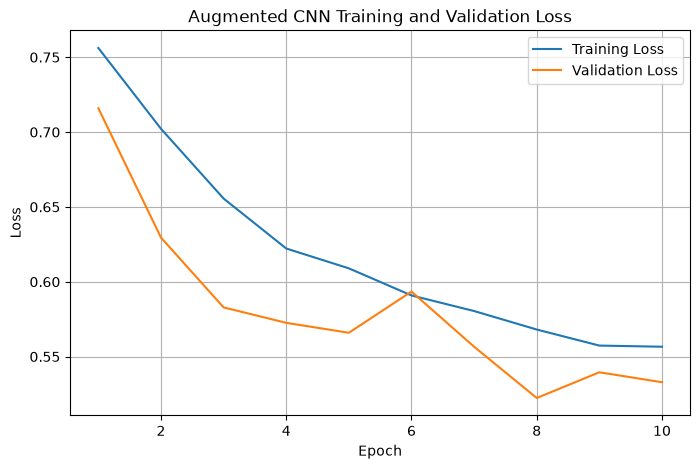

In [32]:
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, aug_train_losses, label="Training Loss")
plt.plot(epochs, aug_val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Augmented CNN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

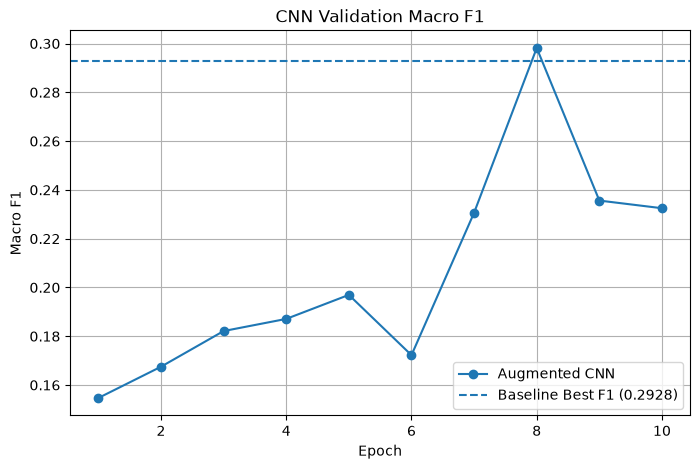

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(epochs, aug_val_f1_scores, marker="o", label="Augmented CNN")
plt.axhline(y=0.2928, linestyle="--", label="Baseline Best F1 (0.2928)")

plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("CNN Validation Macro F1")
plt.legend()
plt.grid(True)
plt.show()

In [40]:
results = {
    "Experiment": [
        "Baseline",
        "Data Augmentation",
        "Learning Rate 0.0005",
        "Learning Rate 0.0001",
        "Dropout 0.5",
        "4-Block CNN"
    ],
    "Learning Rate": [0.001, 0.001, 0.0005, 0.0001, 0.001, 0.001],
    "Dropout": [0.3, 0.3, 0.3, 0.3, 0.5, 0.3],
    "Augmentation": ["No", "Yes", "Yes", "Yes", "Yes", "Yes"],
    "CNN Blocks": [3, 3, 3, 3, 3, 4],
    "Best Epoch": [10, 8, 10, 8, 8, 10],
    "Macro F1": [0.2928, 0.2982, 0.2789, 0.1814, 0.2044, 0.2941]
}

results_df = pd.DataFrame(results)

display(
    results_df.style.highlight_max(
        subset=["Macro F1"],
        color="lightgreen"
    )
)

,Experiment,Learning Rate,Dropout,Augmentation,CNN Blocks,Best Epoch,Macro F1
0,Baseline,0.001000,0.300000,No,3,10,0.292800
1,Data Augmentation,0.001000,0.300000,Yes,3,8,0.298200
2,Learning Rate 0.0005,0.000500,0.300000,Yes,3,10,0.278900
3,Learning Rate 0.0001,0.000100,0.300000,Yes,3,8,0.181400
4,Dropout 0.5,0.001000,0.500000,Yes,3,8,0.204400
5,4-Block CNN,0.001000,0.300000,Yes,4,10,0.294100


## CNN Test Eval

In [35]:
# Load best CNN from hyperparameter experiments
final_model = BoneMarrowCNN(
    num_classes=7,
    dropout=0.3
).to(device)

final_model.load_state_dict(
    torch.load(
        "best_cnn_augmented.pth",
        map_location=device,
        weights_only=True
    )
)

final_model.eval()

print("Best CNN loaded successfully!")

Best CNN loaded successfully!


In [36]:
test_preds = []
test_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = final_model(images)
        predictions = outputs.argmax(dim=1)

        test_preds.extend(predictions.cpu().numpy())
        test_labels.extend(labels.numpy())

test_accuracy = accuracy_score(test_labels, test_preds)

test_macro_f1 = f1_score(
    test_labels,
    test_preds,
    labels=list(range(len(classes))),
    average="macro",
    zero_division=0
)

print("Test Accuracy:", round(test_accuracy, 4))
print("Test Macro F1:", round(test_macro_f1, 4))

print("\nClassification Report:")
print(classification_report(
    test_labels,
    test_preds,
    labels=list(range(len(classes))),
    target_names=classes,
    zero_division=0
))

Test Accuracy: 0.916
Test Macro F1: 0.3151

Classification Report:
              precision    recall  f1-score   support

         ABE       0.00      0.00      0.00         1
         BLA       0.51      0.41      0.45      1796
         FGC       0.00      0.00      0.00         7
         HAC       0.00      0.00      0.00        61
         KSC       1.00      0.67      0.80         6
         LYI       0.00      0.00      0.00        10
      normal       0.95      0.96      0.95     20306

    accuracy                           0.92     22187
   macro avg       0.35      0.29      0.32     22187
weighted avg       0.91      0.92      0.91     22187



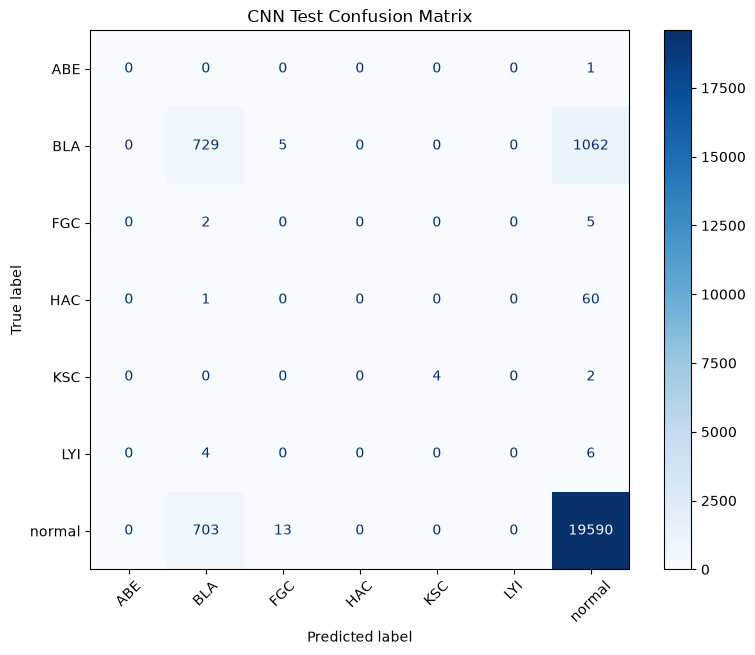

In [37]:
from sklearn.metrics import ConfusionMatrixDisplay

test_cm = confusion_matrix(
    test_labels,
    test_preds,
    labels=list(range(len(classes)))
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=test_cm,
    display_labels=classes
)

disp.plot(ax=ax, cmap="Blues", values_format="d")

plt.title("CNN Test Confusion Matrix")
plt.xticks(rotation=45)
plt.show()

## CNN Error Analysis

Abnormal cells predicted as normal: 1136


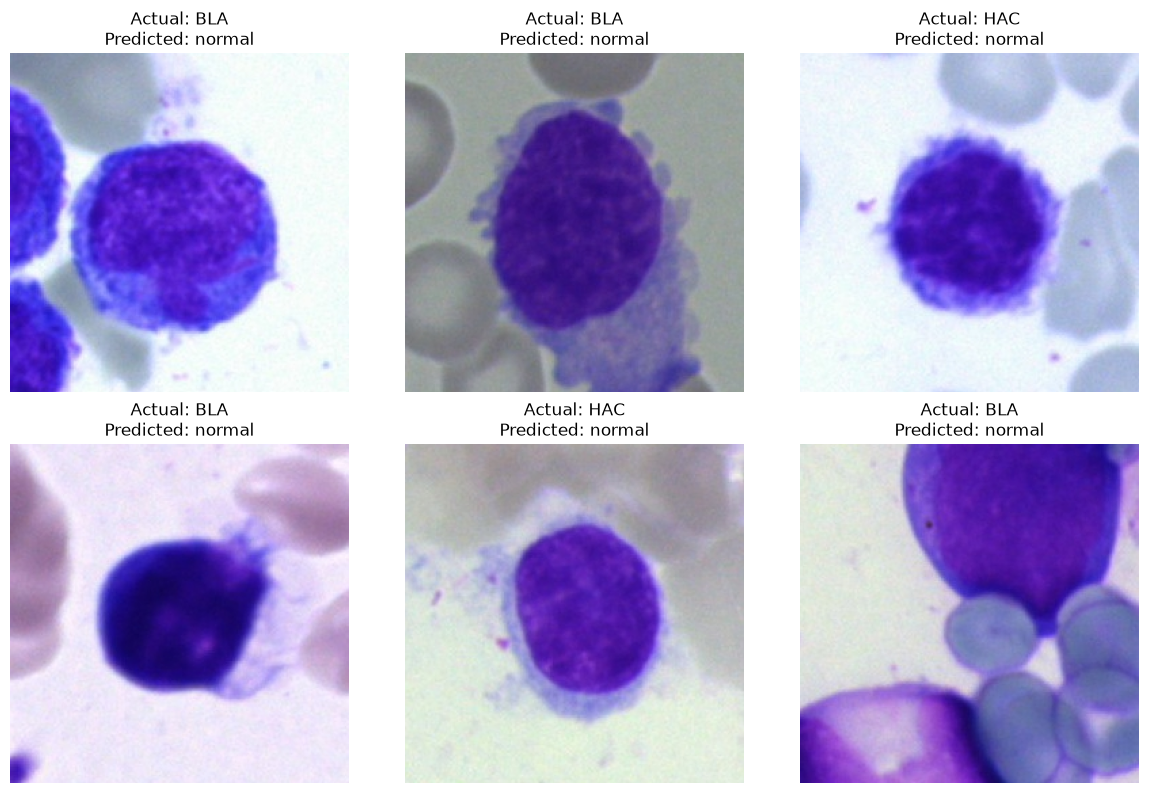

In [38]:
# Find abnormal cells predicted as normal
mistakes = []

for i in range(len(test_labels)):
    true_label = classes[test_labels[i]]
    predicted_label = classes[test_preds[i]]

    if true_label != "normal" and predicted_label == "normal":
        mistakes.append(i)

print("Abnormal cells predicted as normal:", len(mistakes))

# Display the first 6 examples
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, idx in zip(axes.flat, mistakes[:6]):
    image_path = os.path.join(ROOT, test_df.iloc[idx]["filepath"])

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    ax.imshow(image)
    ax.set_title(f"Actual: {classes[test_labels[idx]]}\n"
                 f"Predicted: {classes[test_preds[idx]]}")
    ax.axis("off")

plt.tight_layout()
plt.show()


The CNN performs well on normal cells but struggles to identify several abnormal cell types. From the confusion matrix, 1,062 BLA cells and 60 HAC cells were incorrectly classified as normal. The model also failed to correctly identify any ABE, FGC, HAC, or LYI cells in the test set. This is likely influenced by the large class imbalance, since the model has far more normal images to learn from than abnormal ones. 